# RFMiD — ResNet-152 con los hiperparámetros de Optuna (Disease_Risk)

1. Carga los mejores hiperparámetros de `artifacts/optuna/best_params.json` (notebook `03`).
2. Entrena el modelo final: `train_loss` y `val_loss` por época, *early stopping* y checkpoint por AUC de validación en un archivo **nuevo** (`best_resnet152_disease_risk_optuna.pt`), sin tocar el del baseline.
3. Evalúa en **test**; el umbral de decisión se elige **solo en validación** (índice de Youden) y se compara con el baseline.
4. Grad-CAM sobre el modelo ajustado.

**Nota de cómputo:** sin GPU (CPU, 4 hilos). Con `layer3` descongelado una época a 224 px tarda ~20 min, así que el entrenamiento final se limita a **10 épocas** (`EPOCHS_FINAL`) en lugar de 20; sube el valor si dispones de más tiempo/GPU.

In [1]:
import json
import os
import sys
from pathlib import Path

# Localiza retina_clasificacion/ aunque el cwd del kernel sea el padre Retina/
_cwd = Path.cwd().resolve()
_candidates = [_cwd, *_cwd.parents]
if _cwd.is_dir():
    _candidates.extend(sorted(path for path in _cwd.iterdir() if path.is_dir()))
PROJECT_ROOT = next(
    directory
    for directory in _candidates
    if (directory / "src" / "config.py").is_file() and (directory / "requirements.txt").is_file()
)
sys.path = [entry for entry in sys.path if Path(entry or ".").resolve() != PROJECT_ROOT]
sys.path.insert(0, str(PROJECT_ROOT))
os.environ.setdefault("TORCH_HOME", str(PROJECT_ROOT / "artifacts" / "torch_cache"))

import matplotlib.pyplot as plt
import pandas as pd
from sklearn.metrics import classification_report

from src.config import default_config
from src.data import create_dataloaders
from src.evaluate import (
    collect_predictions,
    compute_classification_metrics,
    select_threshold_youden,
)
from src.explain import compute_gradcam_samples, plot_gradcam_grid
from src.model import load_model
from src.train import get_device, train_model
from src.tuning import build_final_config

device = get_device()
print(f"device={device}")

device=cpu


C:\Users\Xabat Arin\miniconda3\envs\dl\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Hiperparámetros encontrados por Optuna

In [2]:
EPOCHS_FINAL = 10  # 20 en el baseline; reducido por coste en CPU (ver nota arriba)
TUNED_CHECKPOINT_NAME = "best_resnet152_disease_risk_optuna.pt"

best_params_payload = json.loads(
    (PROJECT_ROOT / "artifacts" / "optuna" / "best_params.json").read_text(encoding="utf-8")
)
best_params = best_params_payload["best_params"]
print(f"AUC de validación en la búsqueda (régimen reducido): {best_params_payload['best_val_auc_reduced_regime']:.4f}")
pd.Series(best_params, name="valor").to_frame()

AUC de validación en la búsqueda (régimen reducido): 0.9432


,valor
learning_rate,0.000462
weight_decay,0.000007
focal_gamma,1.36365
focal_alpha,0.260043
batch_size,16
unfreeze_layer3,True
lr_scheduler,plateau


In [3]:
baseline_config = default_config()
tuned_config = build_final_config(baseline_config, best_params, TUNED_CHECKPOINT_NAME)
tuned_config.epochs = EPOCHS_FINAL

print(
    f"epochs={tuned_config.epochs}, batch_size={tuned_config.batch_size}, lr={tuned_config.learning_rate:.2e}, "
    f"scheduler={tuned_config.lr_scheduler}, unfreeze_layer3={tuned_config.unfreeze_layer3}, "
    f"image_size={tuned_config.image_size}"
)

(
    train_loader,
    val_loader,
    test_loader,
    train_dataframe,
    val_dataframe,
    test_dataframe,
) = create_dataloaders(tuned_config)
for name, dataframe in [("train", train_dataframe), ("val", val_dataframe), ("test", test_dataframe)]:
    print(name, len(dataframe), dataframe["disease_risk"].value_counts().to_dict())

epochs=10, batch_size=16, lr=4.62e-04, scheduler=plateau, unfreeze_layer3=True, image_size=224
train 1920 {1: 1519, 0: 401}
val 640 {1: 506, 0: 134}
test 640 {1: 506, 0: 134}


## 2. Entrenamiento final

Cada época imprime `train_loss` y `val_loss`. Si ya existe el checkpoint ajustado no se reentrena (el historial se recarga de `artifacts/logs/tuned_history.json`).

In [4]:
FORCE_RETRAIN = False

tuned_checkpoint_path = tuned_config.checkpoint_dir / tuned_config.best_checkpoint_name
history_path = PROJECT_ROOT / "artifacts" / "logs" / "tuned_history.json"
history_path.parent.mkdir(parents=True, exist_ok=True)

if FORCE_RETRAIN or not (tuned_checkpoint_path.is_file() and history_path.is_file()):
    training_history: list[dict] = []
    train_model(train_loader, val_loader, tuned_config, history=training_history)
    history_path.write_text(json.dumps(training_history, indent=2), encoding="utf-8")
else:
    training_history = json.loads(history_path.read_text(encoding="utf-8"))
    print(f"Checkpoint existente, se omite el entrenamiento: {tuned_checkpoint_path}")

Dispositivo: cpu
Backbone: ResNet-152 (no existe ResNet-150 en torchvision)
Épocas: 10
Parámetros entrenables: 55,580,673 / 58,145,857
Política de congelación:
  - conv1: congelado
  - bn1: congelado
  - relu: sin parámetros
  - maxpool: sin parámetros
  - layer1: congelado
  - layer2: congelado
  - layer3: entrenable
  - layer4: entrenable
  - avgpool: sin parámetros
  - fc: entrenable


Epoch 01/10 | train_loss=0.0716 | val_loss=0.0541 | AUC=0.9244 | F1=0.8508 | Acc=0.7906


  → Nuevo mejor modelo (auc=0.9244) guardado en C:\Users\Xabat Arin\Desktop\kaggle\Retina\artifacts\checkpoints\best_resnet152_disease_risk_optuna.pt


Epoch 02/10 | train_loss=0.0562 | val_loss=0.0504 | AUC=0.9294 | F1=0.9155 | Acc=0.8688


  → Nuevo mejor modelo (auc=0.9294) guardado en C:\Users\Xabat Arin\Desktop\kaggle\Retina\artifacts\checkpoints\best_resnet152_disease_risk_optuna.pt


...

Epoch 06/10 | train_loss=0.0543 | val_loss=0.0571 | AUC=0.9239 | F1=0.8226 | Acc=0.7594


Epoch 07/10 | train_loss=0.0484 | val_loss=0.0561 | AUC=0.9134 | F1=0.8832 | Acc=0.8297


Epoch 08/10 | train_loss=0.0431 | val_loss=0.0469 | AUC=0.9247 | F1=0.8966 | Acc=0.8469


Epoch 09/10 | train_loss=0.0416 | val_loss=0.0463 | AUC=0.9289 | F1=0.9053 | Acc=0.8594


Epoch 10/10 | train_loss=0.0387 | val_loss=0.0491 | AUC=0.9288 | F1=0.8792 | Acc=0.8266
Mejor auc de validación: 0.9312


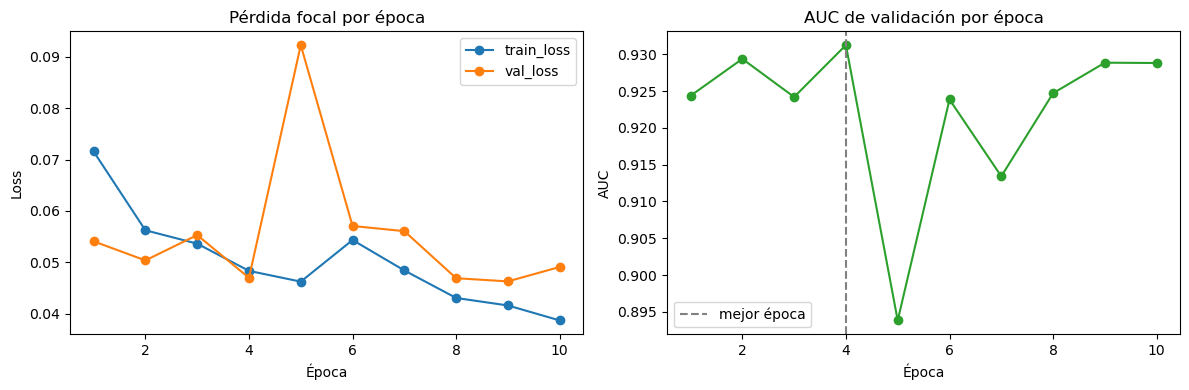

,train_loss,val_loss,val_auc,val_f1,val_accuracy,learning_rate
epoch,,,,,,
1,0.0716,0.0541,0.9244,0.8508,0.7906,0.0005
2,0.0562,0.0504,0.9294,0.9155,0.8688,0.0005
3,0.0536,0.0553,0.9242,0.9208,0.8750,0.0005
4,0.0483,0.0470,0.9312,0.8829,0.8297,0.0005
5,0.0462,0.0923,0.8938,0.8717,0.8156,0.0005
6,0.0543,0.0571,0.9239,0.8226,0.7594,0.0005
7,0.0484,0.0561,0.9134,0.8832,0.8297,0.0005
8,0.0431,0.0469,0.9247,0.8966,0.8469,0.0002
9,0.0416,0.0463,0.9289,0.9053,0.8594,0.0002


In [5]:
history_table = pd.DataFrame(training_history).set_index("epoch")
figure, (loss_axis, auc_axis) = plt.subplots(1, 2, figsize=(12, 4))

loss_axis.plot(history_table.index, history_table["train_loss"], marker="o", label="train_loss")
loss_axis.plot(history_table.index, history_table["val_loss"], marker="o", label="val_loss")
loss_axis.set(title="Pérdida focal por época", xlabel="Época", ylabel="Loss")
loss_axis.legend()

auc_axis.plot(history_table.index, history_table["val_auc"], marker="o", color="tab:green")
auc_axis.axvline(history_table["val_auc"].idxmax(), color="gray", linestyle="--", label="mejor época")
auc_axis.set(title="AUC de validación por época", xlabel="Época", ylabel="AUC")
auc_axis.legend()

plt.tight_layout()
figures_dir = PROJECT_ROOT / "artifacts" / "figures"
figures_dir.mkdir(parents=True, exist_ok=True)
plt.savefig(figures_dir / "tuned_training_curves.png", dpi=110)
plt.show()
history_table.round(4)

## 3. Evaluación: baseline vs ajustado

Se calculan las probabilidades de cada modelo en val y test. El **umbral se elige en validación** (índice de Youden: maximiza TPR − FPR, más adecuado que F1 con 79 % de positivos) y se aplica sin cambios a test. Se incluye también el umbral fijo 0.5 por comparabilidad con las métricas del baseline. El AUC no depende del umbral.

In [6]:
baseline_model = load_model(
    baseline_config.checkpoint_dir / baseline_config.best_checkpoint_name, baseline_config, device
)
tuned_model = load_model(tuned_checkpoint_path, tuned_config, device)

predictions = {}
for model_name, model in [("baseline", baseline_model), ("ajustado", tuned_model)]:
    val_probabilities, val_labels, _ = collect_predictions(model, val_loader, device)
    test_probabilities, test_labels, _ = collect_predictions(model, test_loader, device)
    predictions[model_name] = {
        "val_probabilities": val_probabilities,
        "val_labels": val_labels,
        "test_probabilities": test_probabilities,
        "test_labels": test_labels,
        # Umbral elegido SOLO con validación
        "threshold": select_threshold_youden(val_probabilities, val_labels),
    }
    print(f"{model_name}: umbral (Youden, val) = {predictions[model_name]['threshold']:.3f}")

baseline: umbral (Youden, val) = 0.609


ajustado: umbral (Youden, val) = 0.453


In [7]:
comparison_rows = []
for model_name, model_predictions in predictions.items():
    for split_name in ("val", "test"):
        probabilities = model_predictions[f"{split_name}_probabilities"]
        labels = model_predictions[f"{split_name}_labels"]
        for threshold_name, threshold in [("0.5", 0.5), ("val-Youden", model_predictions["threshold"])]:
            metrics = compute_classification_metrics(probabilities, labels, threshold=threshold)
            comparison_rows.append(
                {
                    "modelo": model_name,
                    "split": split_name,
                    "umbral": f"{threshold_name} ({threshold:.3f})",
                    "AUC": metrics["auc"],
                    "F1": metrics["f1"],
                    "Accuracy": metrics["accuracy"],
                    "matriz_confusion": metrics["confusion_matrix"],
                }
            )
comparison_table = pd.DataFrame(comparison_rows)
comparison_table.round(4)

,modelo,split,umbral,AUC,F1,Accuracy,matriz_confusion
0,baseline,val,0.5 (0.500),0.9313,0.9015,0.8531,"[[116, 18], [76, 430]]"
1,baseline,val,val-Youden (0.609),0.9313,0.8794,0.8281,"[[129, 5], [105, 401]]"
2,baseline,test,0.5 (0.500),0.9610,0.9118,0.8688,"[[122, 12], [72, 434]]"
3,baseline,test,val-Youden (0.609),0.9610,0.8714,0.8188,"[[131, 3], [113, 393]]"
4,ajustado,val,0.5 (0.500),0.9312,0.8829,0.8297,"[[120, 14], [95, 411]]"
5,ajustado,val,val-Youden (0.453),0.9312,0.9022,0.8547,"[[118, 16], [77, 429]]"
6,ajustado,test,0.5 (0.500),0.9640,0.9147,0.8750,"[[131, 3], [77, 429]]"
7,ajustado,test,val-Youden (0.453),0.9640,0.9253,0.8891,"[[129, 5], [66, 440]]"


In [8]:
# Vista compacta del TEST (la comparación que importa), ordenada por umbral
test_comparison = (
    comparison_table[comparison_table["split"] == "test"]
    .drop(columns="split")
    .sort_values(["umbral", "modelo"])
    .round(4)
)
test_comparison

,modelo,umbral,AUC,F1,Accuracy,matriz_confusion
6,ajustado,0.5 (0.500),0.964,0.9147,0.8750,"[[131, 3], [77, 429]]"
2,baseline,0.5 (0.500),0.961,0.9118,0.8688,"[[122, 12], [72, 434]]"
7,ajustado,val-Youden (0.453),0.964,0.9253,0.8891,"[[129, 5], [66, 440]]"
3,baseline,val-Youden (0.609),0.961,0.8714,0.8188,"[[131, 3], [113, 393]]"


Modelo ajustado, TEST, umbral=0.453 (elegido en validación)

              precision    recall  f1-score   support

    sano (0)     0.6615    0.9627    0.7842       134
  riesgo (1)     0.9888    0.8696    0.9253       506

    accuracy                         0.8891       640
   macro avg     0.8252    0.9161    0.8548       640
weighted avg     0.9203    0.8891    0.8958       640



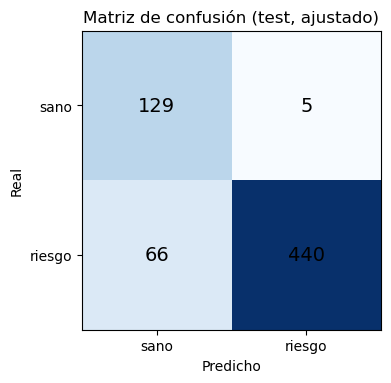

In [9]:
tuned_predictions = predictions["ajustado"]
tuned_threshold = tuned_predictions["threshold"]
test_predicted_labels = (tuned_predictions["test_probabilities"] >= tuned_threshold).astype(int)

print(f"Modelo ajustado, TEST, umbral={tuned_threshold:.3f} (elegido en validación)\n")
print(
    classification_report(
        tuned_predictions["test_labels"].astype(int),
        test_predicted_labels,
        target_names=["sano (0)", "riesgo (1)"],
        digits=4,
    )
)

confusion = compute_classification_metrics(
    tuned_predictions["test_probabilities"], tuned_predictions["test_labels"], tuned_threshold
)["confusion_matrix"]
figure, axis = plt.subplots(figsize=(4, 4))
axis.imshow(confusion, cmap="Blues")
for row in range(2):
    for column in range(2):
        axis.text(column, row, confusion[row][column], ha="center", va="center", fontsize=14)
axis.set(
    xticks=[0, 1], yticks=[0, 1],
    xticklabels=["sano", "riesgo"], yticklabels=["sano", "riesgo"],
    xlabel="Predicho", ylabel="Real", title="Matriz de confusión (test, ajustado)",
)
plt.tight_layout()
plt.savefig(figures_dir / "tuned_confusion_matrix_test.png", dpi=110)
plt.show()

## 4. Grad-CAM del modelo ajustado (test)

Mismo método que en `02_train_resnet152.ipynb` (`src/explain.py`, hooks sobre `layer4[-1]`). Se usa el umbral elegido en validación para definir TP / TN / FP / FN; se muestran los cuatro ejemplos más confiados de cada grupo. Figuras en `artifacts/gradcam/tuned_*.png`.

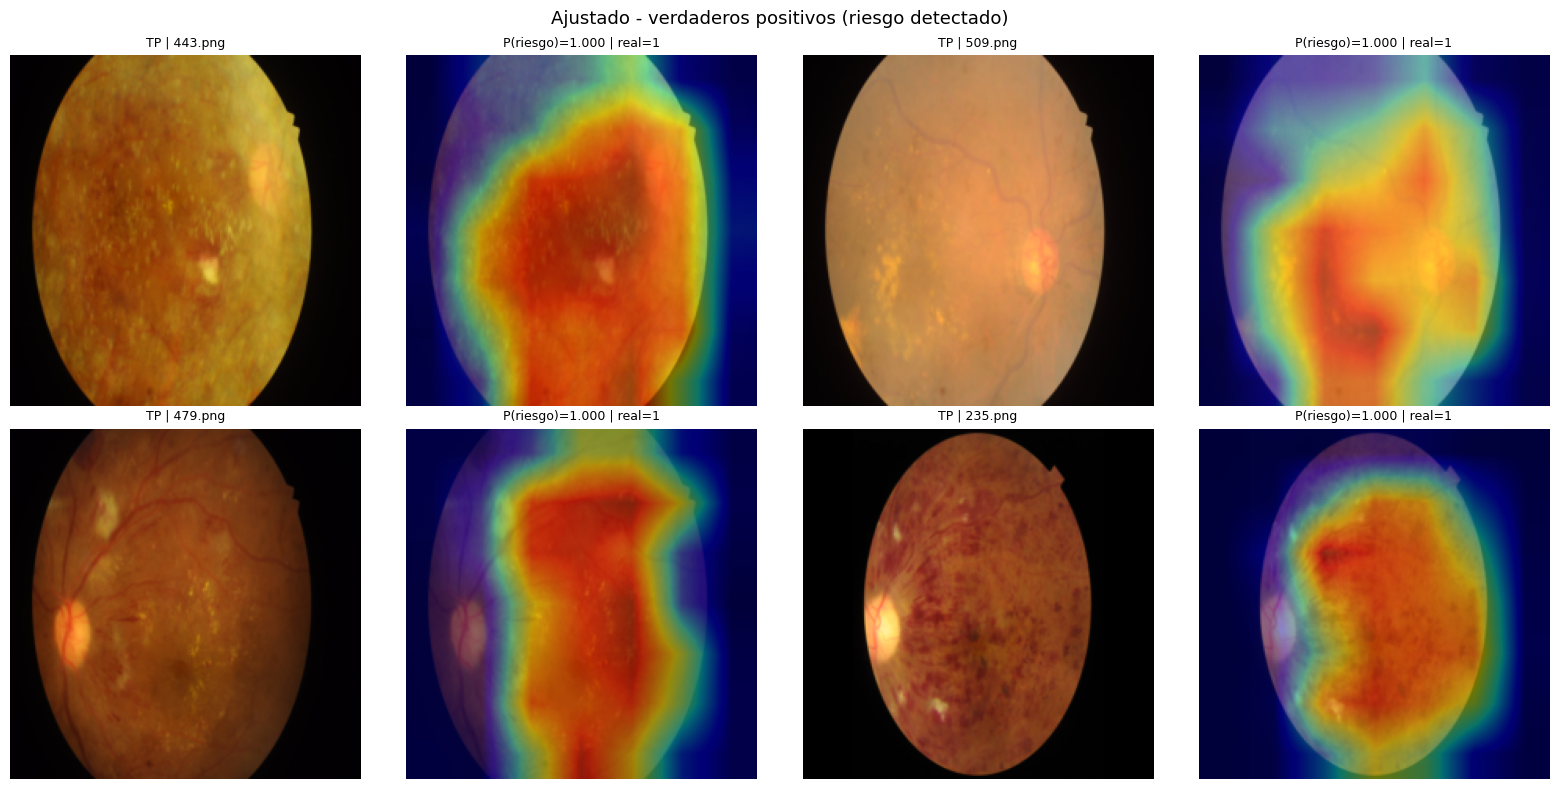

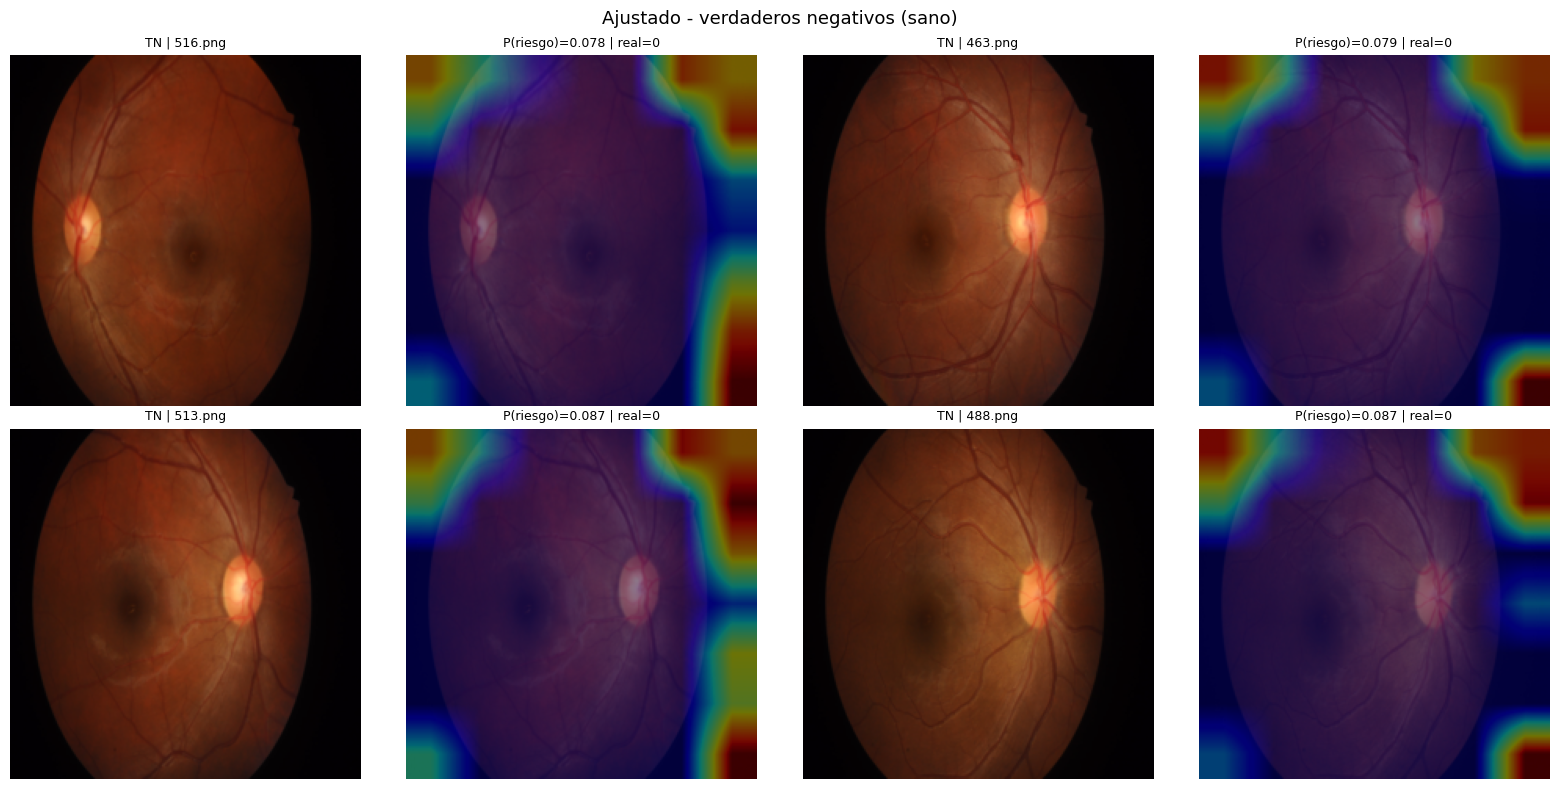

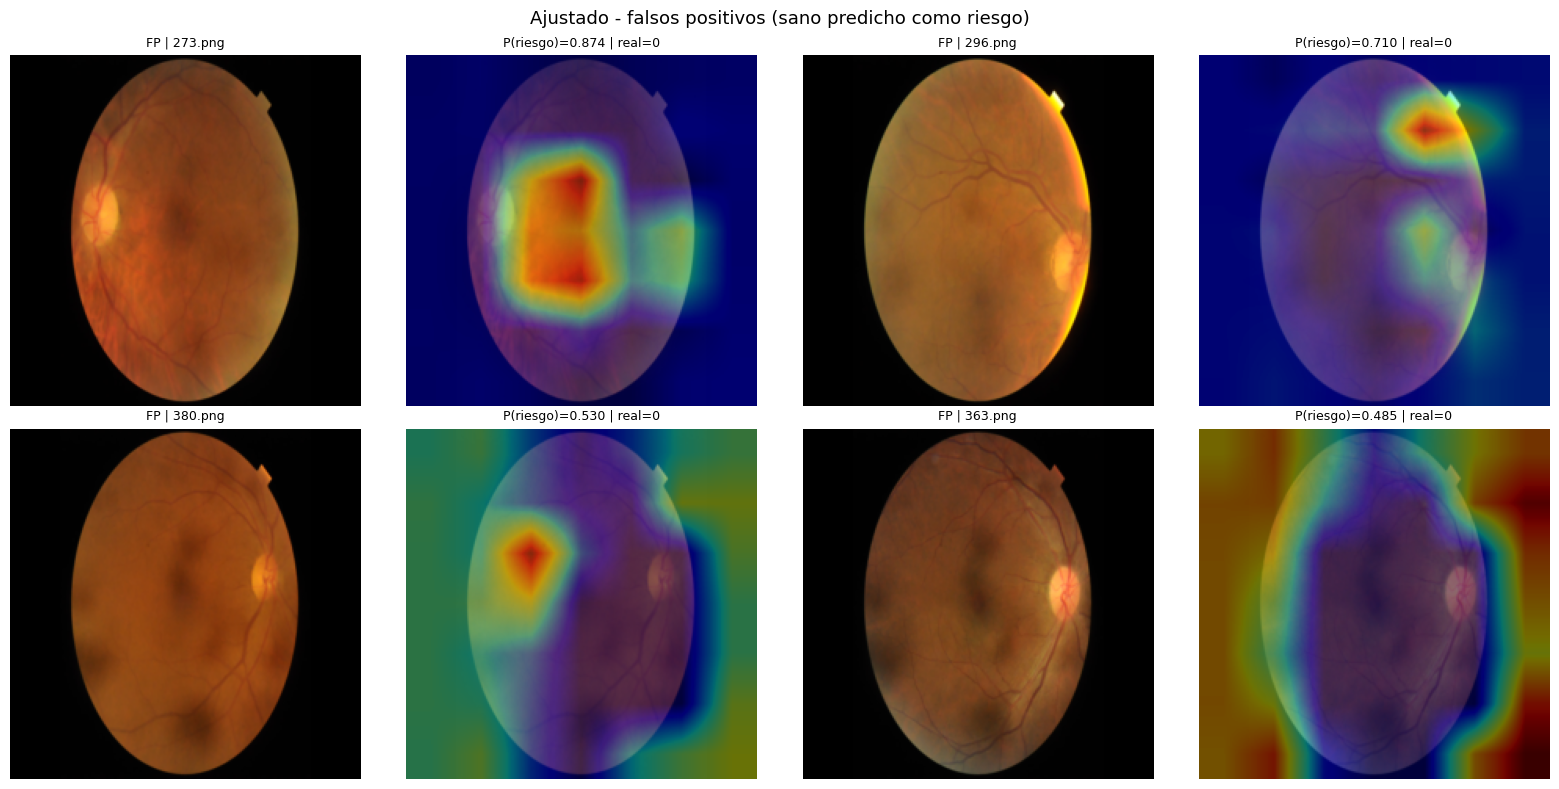

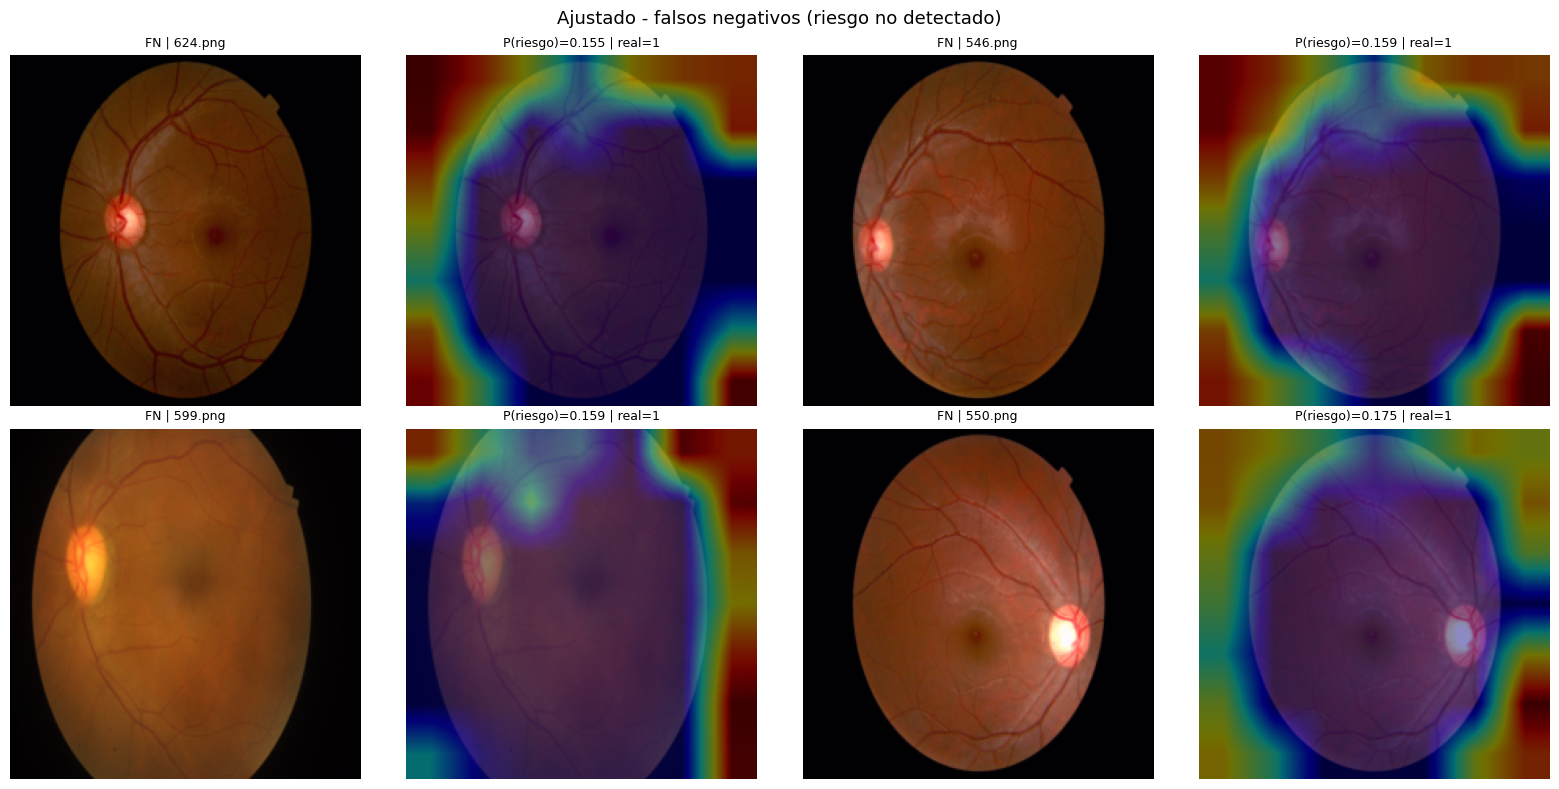

In [10]:
GRADCAM_DIR = PROJECT_ROOT / "artifacts" / "gradcam"

gradcam_samples = compute_gradcam_samples(
    tuned_model,
    test_dataframe,
    tuned_predictions["test_probabilities"],
    tuned_predictions["test_labels"],
    threshold=tuned_threshold,
    image_size=tuned_config.image_size,
    examples_per_group=4,
)
group_titles = {
    "TP": "Ajustado - verdaderos positivos (riesgo detectado)",
    "TN": "Ajustado - verdaderos negativos (sano)",
    "FP": "Ajustado - falsos positivos (sano predicho como riesgo)",
    "FN": "Ajustado - falsos negativos (riesgo no detectado)",
}
for group, group_title in group_titles.items():
    group_samples = [s for s in gradcam_samples if s["group"] == group]
    figure = plot_gradcam_grid(
        group_samples, title=group_title, save_path=GRADCAM_DIR / f"tuned_{group}.png"
    )
    if figure is not None:
        plt.show()